<a href="https://colab.research.google.com/github/kristinalatish/machine-learning/blob/main/%D0%9B%D0%A0_2_2_%D0%9B%D0%B0%D1%82%D0%B8%D1%88_%D0%A4%D0%86%D0%A23_12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота 2.2. Аналіз даних з pandas

**Виконала:** Латиш Крістіна Андріївна, група ФІТ 3-12, № за списком 15

Датасети:
1. Титанік: https://www.kaggle.com/datasets/mahmoudshogaa/titanic-dataset
2. Книги-бестселери Amazon (Top 50, 2009-2019): https://www.kaggle.com/datasets/sootersaalu/amazon-top-50-bestselling-books-2009-2019

## Завдання 1. Аналіз даних про пасажирів Титаніка

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

Завантаження датасету з Kaggle.

In [2]:
import kagglehub
import os

# завантаження датасету
path = kagglehub.dataset_download("mahmoudshogaa/titanic-dataset")

print("Path to dataset files:", path)

100%|██████████| 22.0k/22.0k [00:00<00:00, 24.8MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/mahmoudshogaa/titanic-dataset/versions/1


In [3]:
df = pd.read_csv(os.path.join(path, "titanic.csv"))

df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


1. Виводжу перші 5 рядків

In [4]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Що означають колонки:
- **PassengerId**: номер пасажира
- **Survived**: вижив (1) чи ні (0)
- **Pclass**: клас квитка (1 найвищий, 3 найнижчий)
- **Name**: ім'я
- **Sex**: стать
- **Age**: вік (є пропуски)
- **SibSp**: кількість братів, сестер або подружжя на борту
- **Parch**: кількість батьків або дітей на борту
- **Ticket**: номер квитка
- **Fare**: ціна квитка

2-3. Розмір датасету та типи колонок

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


У датасеті 891 рядок і 12 колонок. Перевіряю дублікати, їх немає:

In [6]:
df.duplicated().sum()

np.int64(0)

4. Перевірка на пропущені значення

In [7]:
# пропуски по колонках
df.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


Пропущені значення є в колонках Age, Cabin і Embarked. Для Age підставила медіану, а Cabin та Embarked видалила, бо вони не потрібні для подальшого аналізу.

In [8]:
# пропуски у віці заповнюю медіаною
df['Age'] = df['Age'].fillna(df['Age'].median())

# видаляю Cabin і Embarked
df = df.drop(columns=['Cabin', 'Embarked'])

5. Повторна перевірка пропусків

In [9]:
df.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0


6. Відбираю колонки для аналізу: Survived, Pclass, Sex, Age, Fare

In [10]:
# відбираю потрібні колонки
df = df[['Survived', 'Pclass', 'Sex', 'Age', 'Fare']].copy()

df.head()

,Survived,Pclass,Sex,Age,Fare
0,0,3,male,22.0,7.2500
1,1,1,female,38.0,71.2833
2,1,3,female,26.0,7.9250
3,1,1,female,35.0,53.1000
4,0,3,male,35.0,8.0500


7. Кодую стать числами 0 і 1. Спершу перевіряю унікальні значення:

In [11]:
df['Sex'].value_counts()

,count
Sex,
male,577
female,314


Є тільки male і female, тому male = 0, female = 1.

In [12]:
# кодую стать
df['Sex'] = df['Sex'].map({'male': 0, 'female': 1})

print(f'Data types of the dataset:\n{df.dtypes}')

Data types of the dataset:
Survived      int64
Pclass        int64
Sex           int64
Age         float64
Fare        float64
dtype: object


8. Описова статистика

In [13]:
df.describe()

,Survived,Pclass,Sex,Age,Fare
count,891.000000,891.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,0.352413,29.361582,32.204208
std,0.486592,0.836071,0.477990,13.019697,49.693429
min,0.000000,1.000000,0.000000,0.420000,0.000000
25%,0.000000,2.000000,0.000000,22.000000,7.910400
50%,0.000000,3.000000,0.000000,28.000000,14.454200
75%,1.000000,3.000000,1.000000,35.000000,31.000000
max,1.000000,3.000000,1.000000,80.000000,512.329200


9. Пропущених значень не залишилось

In [14]:
df.isnull().sum()

,0
Survived,0
Pclass,0
Sex,0
Age,0
Fare,0


10. Перші 5 рядків

In [15]:
df.head()

,Survived,Pclass,Sex,Age,Fare
0,0,3,0,22.0,7.2500
1,1,1,1,38.0,71.2833
2,1,3,1,26.0,7.9250
3,1,1,1,35.0,53.1000
4,0,3,0,35.0,8.0500


11. Останні 5 рядків

In [16]:
df.tail()

,Survived,Pclass,Sex,Age,Fare
886,0,2,0,27.0,13.00
887,1,1,1,19.0,30.00
888,0,3,1,28.0,23.45
889,1,1,0,26.0,30.00
890,0,3,0,32.0,7.75


12. Частка тих, хто вижив, за статтю

In [17]:
sex_surv = df.groupby('Sex')['Survived'].mean() * 100

print(f'Share of survived males: {sex_surv[0]:.2f}%')
print(f'Share of survived females: {sex_surv[1]:.2f}%')

Share of survived males: 18.89%
Share of survived females: 74.20%


In [18]:
print(f'Correlation between sex and survival: {df["Sex"].corr(df["Survived"])}')

Correlation between sex and survival: 0.5433513806577555


Різниця між статями дуже помітна: вижило 74.2% жінок і лише 18.9% чоловіків. Коефіцієнт кореляції статі з виживанням 0.54.

13. Частка тих, хто вижив, за класом

In [19]:
# рахую частку тих, хто вижив, для кожного класу
for cls in [1, 2, 3]:
    rate = df[df['Pclass'] == cls]['Survived'].mean()
    print(f'Share of survived class {cls} passengers: {rate * 100:.2f}%')

Share of survived class 1 passengers: 62.96%
Share of survived class 2 passengers: 47.28%
Share of survived class 3 passengers: 24.24%


У першому класі вижило найбільше пасажирів (63%), у третьому найменше (24%).

14. Середній вік пасажирів, які вижили і не вижили

In [20]:
survived_mean_age = df[df['Survived'] == 1]['Age'].mean()
not_survived_mean_age = df[df['Survived'] == 0]['Age'].mean()

print(f'Mean age of survived passengers: {survived_mean_age:.2f}')
print(f'Mean age of not survived passengers: {not_survived_mean_age:.2f}')

Mean age of survived passengers: 28.29
Mean age of not survived passengers: 30.03


Середній вік 28.3 і 30.0 років, різниця незначна. Отже, середній вік на виживання майже не впливає.

15. Частка тих, хто вижив, за рівнем тарифу

In [21]:
# розбиваю пасажирів на 4 групи (квартилі) за ціною квитка
df['Fare_Category'] = pd.qcut(df['Fare'], 4, labels=False)

# частка тих, хто вижив, у кожній групі
for i in range(4):
    group = df[df['Fare_Category'] == i]
    surv_rate = group['Survived'].mean()
    print(f'Share of survived passengers in bucket {i}: {surv_rate * 100:.2f}%')

Share of survived passengers in bucket 0: 19.73%
Share of survived passengers in bucket 1: 30.36%
Share of survived passengers in bucket 2: 45.50%
Share of survived passengers in bucket 3: 58.11%


Зі зростанням ціни квитка шанси вижити ростуть: у найдешевшій групі вижило близько 20%, у найдорожчій 58%.

16. Медіанний тариф за класами

In [22]:
# медіанна ціна квитка в кожному класі
class_fare = df.groupby('Pclass')['Fare'].median()

for cls, fare in class_fare.items():
    print(f'Median fare for class {cls}: {fare:.2f}')

Median fare for class 1: 60.29
Median fare for class 2: 14.25
Median fare for class 3: 8.05


Різниця значна: перший клас приблизно в 4 рази дорожчий за другий, а другий приблизно в 2 рази дорожчий за третій.

17. Графік: вік і виживання

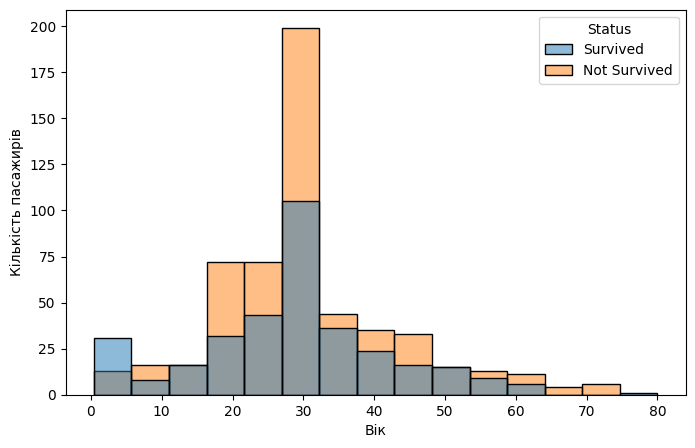

In [23]:
# готую дані для графіка
df_survived = df[df['Survived'] == 1][['Age']]
df_survived['Status'] = 'Survived'

df_not_survived = df[df['Survived'] == 0][['Age']]
df_not_survived['Status'] = 'Not Survived'

df_combined = pd.concat([df_survived, df_not_survived])

# гістограма
plt.figure(figsize=(8, 5))
sns.histplot(data=df_combined, x='Age', hue='Status', bins=15)
plt.xlabel('Вік')
plt.ylabel('Кількість пасажирів')
plt.show()

Висновки з гістограми:
- найбільше пасажирів віком 20-30 років, і серед них значно більше тих, хто не вижив;
- серед дітей до 20 років частка тих, хто вижив, вища, ймовірно дітей рятували в першу чергу;
- у віці 30-50 років загиблих теж більше, але різниця менша;
- після 50 років пасажирів мало, і тих, хто вижив, приблизно стільки ж, скільки загиблих;
- старших за 70 зовсім небагато.

Отже, хоча середній вік у двох групах майже однаковий, за віковими групами видно, що діти мали більше шансів, а найбільше загинуло молодих дорослих 20-30 років.

Додатково зведена таблиця виживання за класом і статтю (у %):

In [24]:
# зведена таблиця: клас x стать
class_sex = pd.pivot_table(df, index='Pclass', columns='Sex', values='Survived', aggfunc='mean') * 100
class_sex = class_sex.rename(columns={0: 'male', 1: 'female'}).round(2)
class_sex

Sex,male,female
Pclass,,
1,36.89,96.81
2,15.74,92.11
3,13.54,50.00


Матриця кореляції ознак:

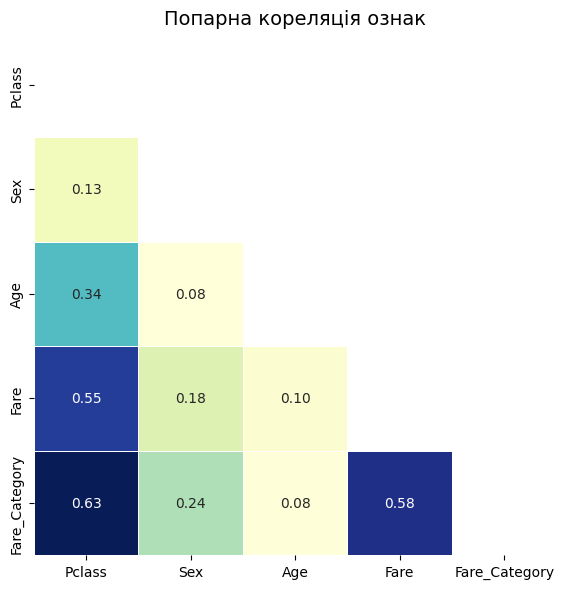

In [25]:
corr_mtx = df.drop('Survived', axis=1).corr(numeric_only=True).abs()

# теплова карта
fig, ax = plt.subplots(figsize=(7, 6))

sns.heatmap(
    corr_mtx,
    cmap='YlGnBu',
    annot=True,
    fmt=".2f",
    linewidths=0.5,
    mask=np.triu(np.ones_like(corr_mtx, dtype=bool)),  # приховую верхній трикутник
    square=True,
    cbar=False,
    ax=ax
)

plt.title("Попарна кореляція ознак", fontsize=14)
plt.tight_layout()
plt.show()

**Висновок.** Головні фактори виживання: стать і клас. Серед жінок першого і другого класу вижили майже всі (97% і 92%), а серед чоловіків другого і третього класу лише 16% і 14%. Пасажири з дорожчими квитками також мали більше шансів. Клас найсильніше корелює з ціною квитка (0.55, а з групою тарифу 0.63).

## Завдання 2. Аналіз бестселерів Amazon

In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

Завантаження датасету з Kaggle

In [27]:
import kagglehub
import os

# завантаження датасету
path = kagglehub.dataset_download("sootersaalu/amazon-top-50-bestselling-books-2009-2019")

print("Path to dataset files:", path)

100%|██████████| 14.5k/14.5k [00:00<00:00, 19.3MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/sootersaalu/amazon-top-50-bestselling-books-2009-2019/versions/1


In [28]:
df = pd.read_csv(os.path.join(path, "bestsellers with categories.csv"))

df

,Name,Author,User Rating,Reviews,Price,Year,Genre
0,10-Day Green Smoothie Cleanse,JJ Smith,4.7,17350,8,2016,Non Fiction
1,11/22/63: A Novel,Stephen King,4.6,2052,22,2011,Fiction
2,12 Rules for Life: An Antidote to Chaos,Jordan B. Peterson,4.7,18979,15,2018,Non Fiction
3,1984 (Signet Classics),George Orwell,4.7,21424,6,2017,Fiction
4,"5,000 Awesome Facts (About Everything!) (Natio...",National Geographic Kids,4.8,7665,12,2019,Non Fiction
...,...,...,...,...,...,...,...
545,Wrecking Ball (Diary of a Wimpy Kid Book 14),Jeff Kinney,4.9,9413,8,2019,Fiction
546,You Are a Badass: How to Stop Doubting Your Gr...,Jen Sincero,4.7,14331,8,2016,Non Fiction
547,You Are a Badass: How to Stop Doubting Your Gr...,Jen Sincero,4.7,14331,8,2017,Non Fiction
548,You Are a Badass: How to Stop Doubting Your Gr...,Jen Sincero,4.7,14331,8,2018,Non Fiction


Датасет містить 550 записів і 7 колонок:
- **Name**: назва книги
- **Author**: автор
- **User Rating**: середня оцінка користувачів
- **Reviews**: кількість відгуків
- **Price**: ціна
- **Year**: рік потрапляння в рейтинг
- **Genre**: жанр (Fiction або Non Fiction)

Перші 5 записів

In [29]:
df.head()

,Name,Author,User Rating,Reviews,Price,Year,Genre
0,10-Day Green Smoothie Cleanse,JJ Smith,4.7,17350,8,2016,Non Fiction
1,11/22/63: A Novel,Stephen King,4.6,2052,22,2011,Fiction
2,12 Rules for Life: An Antidote to Chaos,Jordan B. Peterson,4.7,18979,15,2018,Non Fiction
3,1984 (Signet Classics),George Orwell,4.7,21424,6,2017,Fiction
4,"5,000 Awesome Facts (About Everything!) (Natio...",National Geographic Kids,4.8,7665,12,2019,Non Fiction


Кількість рядків і колонок

In [30]:
df.shape

(550, 7)

In [31]:
df.duplicated().sum()

np.int64(0)

Повних дублікатів немає, проте одна й та сама книга могла бути в топі кілька років. Рахую повтори за назвою та видаляю їх:

In [32]:
df.duplicated(subset='Name').sum()

np.int64(199)

In [33]:
df = df.drop_duplicates(subset='Name')

In [34]:
df.shape

(351, 7)

Про скільки книг дані? 550 записів, з них 351 унікальна книга.

Перейменовую колонки: маленькі літери, пробіли замінюю на _.

In [35]:
df.columns = ['name', 'author', 'user_rating', 'reviews', 'price', 'year', 'genre']
df.head()

,name,author,user_rating,reviews,price,year,genre
0,10-Day Green Smoothie Cleanse,JJ Smith,4.7,17350,8,2016,Non Fiction
1,11/22/63: A Novel,Stephen King,4.6,2052,22,2011,Fiction
2,12 Rules for Life: An Antidote to Chaos,Jordan B. Peterson,4.7,18979,15,2018,Non Fiction
3,1984 (Signet Classics),George Orwell,4.7,21424,6,2017,Fiction
4,"5,000 Awesome Facts (About Everything!) (Natio...",National Geographic Kids,4.8,7665,12,2019,Non Fiction


Пропусків у даних немає:

In [36]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 351 entries, 0 to 546
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   name         351 non-null    object 
 1   author       351 non-null    object 
 2   user_rating  351 non-null    float64
 3   reviews      351 non-null    int64  
 4   price        351 non-null    int64  
 5   year         351 non-null    int64  
 6   genre        351 non-null    object 
dtypes: float64(1), int64(3), object(3)
memory usage: 21.9+ KB


In [37]:
df.isna().sum()

,0
name,0
author,0
user_rating,0
reviews,0
price,0
year,0
genre,0


Жанри в датасеті: Non Fiction і Fiction

In [38]:
df['genre'].value_counts()

,count
genre,
Non Fiction,191
Fiction,160


Гістограма цін

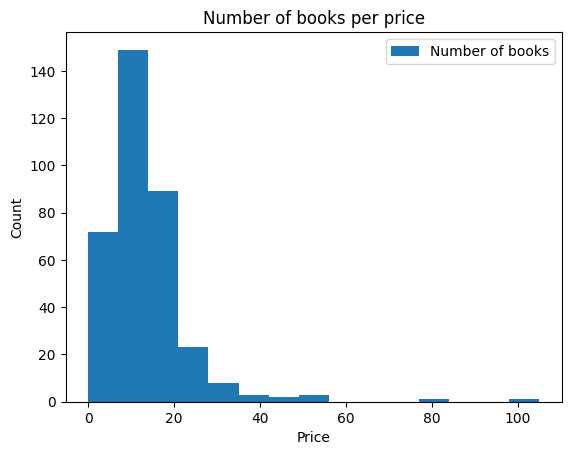

In [39]:
df['price'].plot(kind='hist', bins=15, label='Number of books')
plt.xlabel('Price')
plt.ylabel('Count')
plt.title('Number of books per price')
plt.legend()
plt.show()

Основна частина книг дешевша за 20$.

- Максимальна ціна: 105
- Мінімальна ціна: 0
- Середня ціна: 13.1
- Медіанна ціна: 12

In [40]:
df['price'].describe()

,price
count,351.000000
mean,13.076923
std,10.050860
min,0.000000
25%,8.000000
50%,12.000000
75%,16.000000
max,105.000000


Максимальний рейтинг: 4.9

In [41]:
df['user_rating'].max()

4.9

Кількість книг з таким рейтингом: 28

In [42]:
df[df['user_rating'] == 4.9]['name'].count()

np.int64(28)

Книга з найбільшою кількістю відгуків: Where the Crawdads Sing

In [43]:
df[ df['reviews'] == df['reviews'].max() ]

,name,author,user_rating,reviews,price,year,genre
534,Where the Crawdads Sing,Delia Owens,4.8,87841,15,2019,Fiction


Найдорожча книга в Топ-50 2015 року: Go Set a Watchman: A Novel (19$)

In [44]:
max_price = df[df['year'] == 2015]['price'].max()
df[(df['year'] == 2015) & (df['price'] == max_price)]

,name,author,user_rating,reviews,price,year,genre
132,Go Set a Watchman: A Novel,Harper Lee,3.6,14982,19,2015,Fiction


Кількість книг жанру Fiction у 2010 році: 17

In [45]:
df[(df['year'] == 2010) & (df['genre'] == 'Fiction')]['name'].count()

np.int64(17)

Книг з рейтингом 4.9 у 2010-2011 роках: 1

In [46]:
df[(df['user_rating'] == 4.9) & (df['year'].isin([2010, 2011]))]

,name,author,user_rating,reviews,price,year,genre
187,Jesus Calling: Enjoying Peace in His Presence ...,Sarah Young,4.9,19576,8,2011,Non Fiction


Книги 2015 року з ціною менше 8$, сортування за ціною. Остання в списку: Old School (Diary of a Wimpy Kid #10)

In [47]:
df[(df['price'] < 8) & (df['year'] == 2015)].sort_values('price')

,name,author,user_rating,reviews,price,year,genre
54,Creative Haven Creative Cats Coloring Book (Ad...,Marjorie Sarnat,4.8,4022,4,2015,Non Fiction
123,Giraffes Can't Dance,Giles Andreae,4.8,14038,4,2015,Fiction
55,Creative Haven Owls Coloring Book (Adult Color...,Marjorie Sarnat,4.8,3871,5,2015,Non Fiction
28,Baby Touch and Feel: Animals,DK,4.6,5360,5,2015,Non Fiction
63,Dear Zoo: A Lift-the-Flap Book,Rod Campbell,4.8,10922,5,2015,Fiction
89,Dover Creative Haven Art Nouveau Animal Design...,Marty Noble,4.6,2134,5,2015,Non Fiction
201,Killing Reagan: The Violent Assault That Chang...,Bill O'Reilly,4.6,5235,5,2015,Non Fiction
16,Adult Coloring Book: Stress Relieving Animal D...,Blue Star Coloring,4.6,2925,6,2015,Non Fiction
17,Adult Coloring Book: Stress Relieving Patterns,Blue Star Coloring,4.4,2951,6,2015,Non Fiction
253,Old School (Diary of a Wimpy Kid #10),Jeff Kinney,4.8,6169,7,2015,Fiction


Мінімальна та максимальна ціна для кожного жанру:
- Fiction: від 0 до 82
- Non Fiction: від 0 до 105

In [48]:
df.groupby('genre')['price'].agg(['min', 'max'])

,min,max
genre,,
Fiction,0,82
Non Fiction,0,105


Скільки книг у кожного автора. Розмір таблиці (248, 1), лідер Jeff Kinney (12 книг).

In [49]:
books_per_author = df.groupby('author')[['name']].count()
books_per_author

,name
author,
Abraham Verghese,1
Adam Gasiewski,1
Adam Mansbach,1
Adir Levy,1
Admiral William H. McRaven,1
...,...
Walter Isaacson,2
William Davis,1
William P. Young,1


In [50]:
books_per_author[books_per_author['name'] == books_per_author['name'].max()]

,name
author,
Jeff Kinney,12


Середній рейтинг кожного автора. Найменший у Donna Tartt (3.9).

In [51]:
author_rating = df.groupby('author')[['user_rating']].mean().round(1)
author_rating

,user_rating
author,
Abraham Verghese,4.6
Adam Gasiewski,4.4
Adam Mansbach,4.8
Adir Levy,4.8
Admiral William H. McRaven,4.7
...,...
Walter Isaacson,4.6
William Davis,4.4
William P. Young,4.6


In [52]:
author_rating[author_rating['user_rating'] == author_rating['user_rating'].min()]

,user_rating
author,
Donna Tartt,3.9


Те саме коротше:

In [53]:
author_rating.min()

,0
user_rating,3.9


Об'єдную таблиці, щоб бачити для кожного автора кількість книг і середній рейтинг

In [54]:
authors_info = pd.concat([author_rating, books_per_author], axis=1)
authors_info

,user_rating,name
author,,
Abraham Verghese,4.6,1
Adam Gasiewski,4.4,1
Adam Mansbach,4.8,1
Adir Levy,4.8,1
Admiral William H. McRaven,4.7,1
...,...,...
Walter Isaacson,4.6,2
William Davis,4.4,1
William P. Young,4.6,1


Сортування за кількістю книг і рейтингом. Перший рядок: Donna Tartt

In [55]:
authors_info.sort_values(by=['name', 'user_rating'])

,user_rating,name
author,,
Donna Tartt,3.9,1
Gallup,4.0,1
Gillian Flynn,4.0,1
Muriel Barbery,4.0,1
Chris Cleave,4.1,1
...,...,...
Bill O'Reilly,4.6,6
Dav Pilkey,4.9,6
Stephenie Meyer,4.7,7


**Висновок.** Після видалення повторів у датасеті залишилась 351 книга: 191 Non Fiction і 160 Fiction, пропущених значень немає. Більшість книг коштують менше 20$, медіана ціни 12$. Лідер за кількістю відгуків Where the Crawdads Sing, найбільше книг у Jeff Kinney (12), найнижчий середній рейтинг у Donna Tartt (3.9).